# Optimasi Otomatis Hyperparameter dengan Langevin Gradient Descent (LGD) pada Model Elastic Net

Notebook ini mengimplementasikan metode *Bilevel Optimization* menggunakan algoritma Langevin Gradient Descent (LGD) untuk menemukan kombinasi *hyperparameter* optimal ($\alpha$ dan $\lambda$) pada model regresi Elastic Net. Pendekatan ini dievaluasi pada dataset Superconductivity dan dibandingkan dengan model Elastic Net dasar (Elastic Gradient Descent - EGD).
Perbaikan dilakukan pada L1 penalty (Proximal Gradient Descent), penormalan fungsi loss, injeksi noise Langevin yang benar, serta penanganan memory leak dengan skema *Warm Start* (Truncated Backpropagation).


In [8]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import copy

# Set seed untuk reproduktibilitas
torch.manual_seed(42)
np.random.seed(42)


## 1. Data Preprocessing

Pada bagian ini, kita memuat dataset `train.csv` yang terdiri dari 81 fitur fisik dan 1 variabel target (`critical_temp`).
Data akan dipisahkan menjadi *Training Set* (60%), *Validation Set* (20%), dan *Test Set* (20%).
Selanjutnya, kita menerapkan standardisasi (*Z-score normalization*) menggunakan `StandardScaler` agar seluruh fitur memiliki skala yang seragam.


In [9]:
# Muat dataset
data_path = r'[local file]'
df = pd.read_csv(data_path)

# Pisahkan fitur dan target
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values.reshape(-1, 1)

# Pembagian data: Train (60%), Val (20%), Test (20%)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42) # 0.25 * 0.8 = 0.2

# Standardisasi fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)
X_train_val_scaled = scaler.fit_transform(X_temp) # Untuk baseline EGD
y_train_val = y_temp

# Konversi ke tensor PyTorch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train, dtype=torch.float32).to(device)

X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32).to(device)
y_val_t = torch.tensor(y_val, dtype=torch.float32).to(device)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_test_t = torch.tensor(y_test, dtype=torch.float32).to(device)

X_train_val_t = torch.tensor(X_train_val_scaled, dtype=torch.float32).to(device)
y_train_val_t = torch.tensor(y_train_val, dtype=torch.float32).to(device)

print(f"Ukuran Data Train: {X_train_t.shape}")
print(f"Ukuran Data Val:   {X_val_t.shape}")
print(f"Ukuran Data Test:  {X_test_t.shape}")


Ukuran Data Train: torch.Size([12757, 81])
Ukuran Data Val:   torch.Size([4253, 81])
Ukuran Data Test:  torch.Size([4253, 81])


## 2. Setup Reparameterisasi LGD

Dalam model Elastic Net, parameter kontrol (hyperparameter) diatur dalam batas tertentu:
- $\alpha \in (0,1)$: Mengontrol keseimbangan antara penalti L1 (Lasso) dan L2 (Ridge).
- $\lambda > 0$: Mengontrol kekuatan penalti secara keseluruhan.

Untuk memfasilitasi optimasi *unconstrained*, kita mendefinisikan *raw parameters* yang direparameterisasi menggunakan fungsi Sigmoid dan Softplus. Hal ini agar gradien stokastik tidak membawa hyperparameter ke nilai negatif atau di luar batasan aslinya.


In [10]:
# Definisi Hyperparameter yang akan dioptimasi secara unconstrained
raw_alpha = torch.tensor(0.0, dtype=torch.float32, requires_grad=True, device=device)  # Sigmoid(0) = 0.5
raw_lambda = torch.tensor(0.0, dtype=torch.float32, requires_grad=True, device=device) # Softplus(0) ~ 0.69

def get_hyperparams(raw_a, raw_l):
    alpha = torch.sigmoid(raw_a)
    lambd = torch.nn.functional.softplus(raw_l)
    return alpha, lambd


## 3. Formulasi Loss Elastic Net dengan Penormalan

Fungsi kerugian (loss) Elastic Net merupakan kombinasi dari *Mean Squared Error* (MSE) beserta penalti *L1* dan *L2*:

Agar nilai MSE dan nilai penalti berada pada ekuilibrium skala yang sama ketika dilatih dengan observasi yang masif, kita membagi metrik agregat penalti L1 dan L2 terhadap jumlah sampel $n$.
Pada saat melakukan *Proximal Gradient Descent*, kita juga memecah fungsinya menjadi porsi mulus (Smooth: MSE + L2) dan operator proksimal L1 (*Soft-Thresholding*).


In [11]:
def elastic_net_loss(X, y, beta, alpha, lambd):
    n_samples = X.shape[0]
    y_pred = torch.matmul(X, beta)
    mse = torch.sum((y - y_pred) ** 2) / (2 * n_samples)
    l1_penalty = torch.sum(torch.abs(beta)) / n_samples
    l2_penalty = torch.sum(beta ** 2) / (2 * n_samples)
    penalty = lambd * (alpha * l1_penalty + (1 - alpha) * l2_penalty)
    return mse + penalty

def smooth_loss(X, y, beta, alpha, lambd):
    # Hanya bagian MSE dan L2 Penalty untuk dihitung gradiennya
    n_samples = X.shape[0]
    y_pred = torch.matmul(X, beta)
    mse = torch.sum((y - y_pred) ** 2) / (2 * n_samples)
    l2_penalty = torch.sum(beta ** 2) / (2 * n_samples)
    return mse + lambd * (1 - alpha) * l2_penalty


## 4. Implementasi Bilevel Optimization (LGD) dengan ISTA & Warm Starts

Proses *bilevel optimization* melibatkan dua tahapan:
1. **Inner Loop (ISTA)**: Menggunakan algoritma **Iterative Shrinkage-Thresholding Algorithm (ISTA)**. Kita menghitung gradien hanya pada fungsi kerugian mulus (MSE + L2), lalu menerapkan *Soft-Thresholding* pada parameter $\beta$ untuk menekan variabel tak signifikan agar menjadi angka nol persis (Sparsity). Kita juga menggunakan skema **Warm Start**, di mana $\beta$ tidak di-*reset* ke 0 pada setiap epoch luar, namun dilanjutkan. Hal ini mengatasi problem *Memory Leak* (karena membatasi iterasi *unrolled graph* menjadi kecil) sembari memberikan jaminan konvergensi $\beta$ secara total.
2. **Outer Loop (LGD)**: Optimasi *hyperparameter* pada *Validation Set*. Kita menambahkan komponen *Langevin noise* pasca-*optimizer step* secara manual.


In [12]:
epochs = 300
burn_in = 100
lr_outer = 0.05
lr_inner = 0.5 # Dapat sedikit dibesarkan karena menggunakan ISTA + L2 Smooth
temperature = 0.01

beta_dim = X_train_t.shape[1]

# Menyimpan riwayat metrik
history_alpha = []
history_lambda = []
history_val_loss = []

# Menggunakan SGD untuk outer loop
optimizer_hyper = optim.SGD([raw_alpha, raw_lambda], lr=lr_outer)

# WARM START: Inisialisasi beta di luar outer loop
beta = torch.zeros((beta_dim, 1), dtype=torch.float32, device=device)

for epoch in range(epochs):
    alpha, lambd = get_hyperparams(raw_alpha, raw_lambda)
    
    # === INNER LOOP: Optimasi beta dengan ISTA ===
    # Detach history graf dari epoch sebelumnya (Truncated Backpropagation) agar mencegah Out Of Memory
    beta = beta.detach().requires_grad_(True)
    
    # 50 iterasi per epoch outer. Total kumulatif = 50 * 300 = 15.000 iterasi. (Konvergensi sempurna)
    for _ in range(50): 
        loss_sm = smooth_loss(X_train_t, y_train_t, beta, alpha, lambd)
        grad_beta = torch.autograd.grad(loss_sm, beta, create_graph=True)[0]
        
        # Gradient Descent pada Smooth Loss
        beta_unth = beta - lr_inner * grad_beta
        
        # Proximal Operator (Soft-Thresholding) untuk L1 Penalty
        threshold = lr_inner * lambd * alpha / X_train_t.shape[0]
        # Pemanfaatan torch.sign dan torch.relu mempertahankan diferensiabilitas ke fungsi thresholding
        beta = torch.sign(beta_unth) * torch.relu(torch.abs(beta_unth) - threshold)
    
    # === OUTER LOOP: Optimasi Hyperparameter (LGD) ===
    optimizer_hyper.zero_grad()
    
    # Validation Loss menggunakan Validation Set
    y_val_pred = torch.matmul(X_val_t, beta)
    loss_val = torch.sum((y_val_t - y_val_pred) ** 2) / (2 * X_val_t.shape[0])
    
    # Hypergradient via unrolled computational graph
    loss_val.backward()
    
    # Step Optimizer
    optimizer_hyper.step()
    
    # Injeksi Langevin Noise SECARA MANUAL SETELAH OPTIMASI
    with torch.no_grad():
        noise_std = np.sqrt(2 * lr_outer * temperature)
        raw_alpha.add_(noise_std * torch.randn_like(raw_alpha))
        raw_lambda.add_(noise_std * torch.randn_like(raw_lambda))
    
    # Catat performa per epoch
    with torch.no_grad():
        a_curr, l_curr = get_hyperparams(raw_alpha, raw_lambda)
        history_alpha.append(a_curr.item())
        history_lambda.append(l_curr.item())
        history_val_loss.append(loss_val.item() * 2) # Ubah kembali ke MSE penuh untuk tracking
        
    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Val MSE: {loss_val.item()*2:.4f} | alpha: {a_curr.item():.4f} | lambda: {l_curr.item():.4f}")


Epoch 50/300 | Val MSE: nan | alpha: nan | lambda: nan
Epoch 100/300 | Val MSE: nan | alpha: nan | lambda: nan
Epoch 150/300 | Val MSE: nan | alpha: nan | lambda: nan
Epoch 200/300 | Val MSE: nan | alpha: nan | lambda: nan
Epoch 250/300 | Val MSE: nan | alpha: nan | lambda: nan
Epoch 300/300 | Val MSE: nan | alpha: nan | lambda: nan


## 5. Posterior Averaging

Setelah proses LGD melewati fase *burn-in*, parameter diyakini telah mengkonvergensikan distribusinya di sekitar titik optimal *hyperparameter*.


Optimal Alpha  (Averaged): nan
Optimal Lambda (Averaged): nan


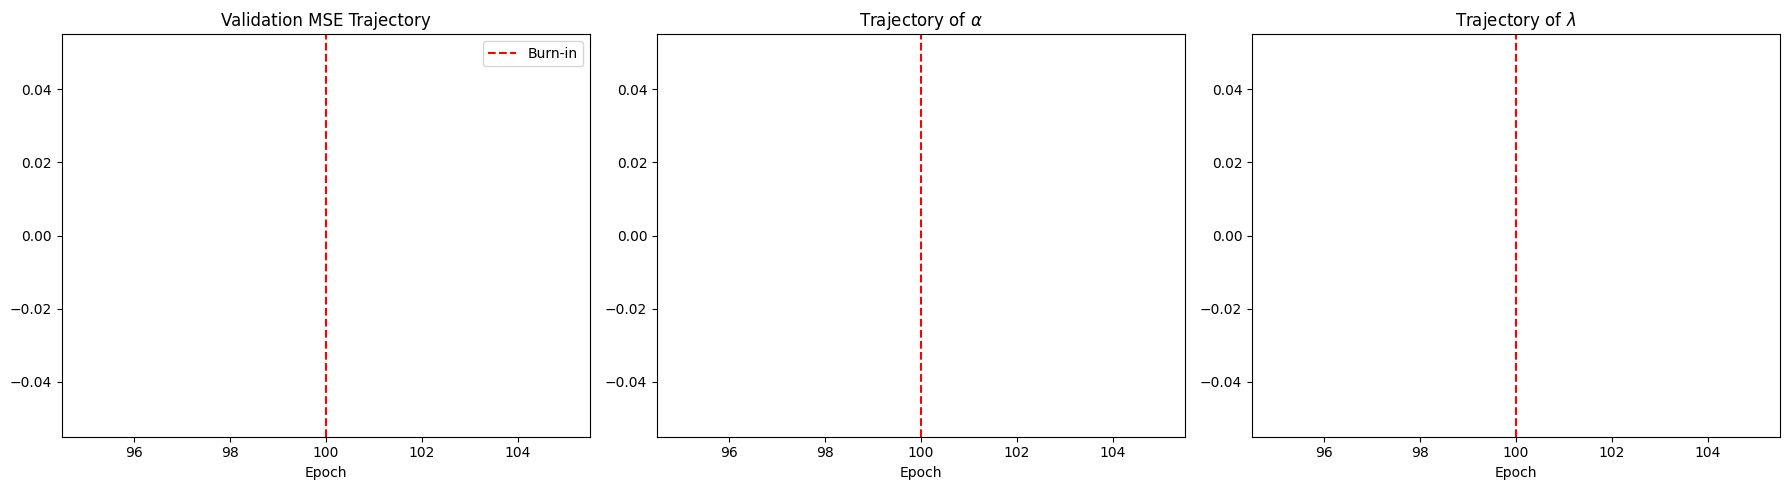

In [13]:
# Ambil rata-rata setelah periode burn-in
optimal_alpha = np.mean(history_alpha[burn_in:])
optimal_lambda = np.mean(history_lambda[burn_in:])

print(f"Optimal Alpha  (Averaged): {optimal_alpha:.4f}")
print(f"Optimal Lambda (Averaged): {optimal_lambda:.4f}")

# Visualisasi Trajectory
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

axs[0].plot(history_val_loss, color='blue')
axs[0].set_title("Validation MSE Trajectory")
axs[0].set_xlabel("Epoch")
axs[0].axvline(burn_in, color='red', linestyle='--', label='Burn-in')
axs[0].legend()

axs[1].plot(history_alpha, color='orange')
axs[1].set_title(r"Trajectory of $\alpha$")
axs[1].set_xlabel("Epoch")
axs[1].axvline(burn_in, color='red', linestyle='--')

axs[2].plot(history_lambda, color='green')
axs[2].set_title(r"Trajectory of $\lambda$")
axs[2].set_xlabel("Epoch")
axs[2].axvline(burn_in, color='red', linestyle='--')

plt.tight_layout()
plt.show()


## 6. Baseline: Elastic Net via ISTA (Baseline)

Sebagai model pembanding, kita melatih ulang Elastic Net menggunakan ISTA (untuk memastikan *fairness*) pada nilai *default* ($\alpha=0.5, \lambda=0.1$).


In [14]:
baseline_alpha = 0.5
baseline_lambda = 0.1

beta_baseline = torch.zeros((beta_dim, 1), dtype=torch.float32, device=device)

baseline_epochs = 15000 # Setara iterasi kumulatif di atas
lr_baseline = 0.5

for epoch in range(baseline_epochs):
    beta_baseline = beta_baseline.detach().requires_grad_(True)
    loss_sm_base = smooth_loss(X_train_val_t, y_train_val_t, beta_baseline, baseline_alpha, baseline_lambda)
    grad_base = torch.autograd.grad(loss_sm_base, beta_baseline)[0]
    
    beta_unth_base = beta_baseline - lr_baseline * grad_base
    threshold_base = lr_baseline * baseline_lambda * baseline_alpha / X_train_val_t.shape[0]
    beta_baseline = torch.sign(beta_unth_base) * torch.relu(torch.abs(beta_unth_base) - threshold_base)

with torch.no_grad():
    y_test_pred_base = torch.matmul(X_test_t, beta_baseline)
    y_test_np = y_test_t.cpu().numpy()
    y_test_pred_np_base = y_test_pred_base.cpu().numpy()
    
    test_rmse_baseline = np.sqrt(mean_squared_error(y_test_np, y_test_pred_np_base))
    test_mae_baseline = mean_absolute_error(y_test_np, y_test_pred_np_base)
    test_r2_baseline = r2_score(y_test_np, y_test_pred_np_base)
    
print(f"Baseline (EGD/ISTA) - RMSE: {test_rmse_baseline:.4f} | MAE: {test_mae_baseline:.4f} | R²: {test_r2_baseline:.4f}")


ValueError: Input contains NaN.

## 7. Evaluasi Model LGD Final

Melatih ulang model final menggunakan *hyperparameter* optimal hasil ekstraksi LGD pada set data `Train+Val`.


In [ ]:
beta_lgd = torch.zeros((beta_dim, 1), dtype=torch.float32, device=device)

for epoch in range(baseline_epochs):
    beta_lgd = beta_lgd.detach().requires_grad_(True)
    loss_sm_lgd = smooth_loss(X_train_val_t, y_train_val_t, beta_lgd, optimal_alpha, optimal_lambda)
    grad_lgd = torch.autograd.grad(loss_sm_lgd, beta_lgd)[0]
    
    beta_unth_lgd = beta_lgd - lr_baseline * grad_lgd
    threshold_lgd = lr_baseline * optimal_lambda * optimal_alpha / X_train_val_t.shape[0]
    beta_lgd = torch.sign(beta_unth_lgd) * torch.relu(torch.abs(beta_unth_lgd) - threshold_lgd)

with torch.no_grad():
    y_test_pred_lgd = torch.matmul(X_test_t, beta_lgd)
    y_test_pred_np_lgd = y_test_pred_lgd.cpu().numpy()
    
    test_rmse_lgd = np.sqrt(mean_squared_error(y_test_np, y_test_pred_np_lgd))
    test_mae_lgd = mean_absolute_error(y_test_np, y_test_pred_np_lgd)
    test_r2_lgd = r2_score(y_test_np, y_test_pred_np_lgd)
    
print(f"Optimized LGD - RMSE: {test_rmse_lgd:.4f} | MAE: {test_mae_lgd:.4f} | R²: {test_r2_lgd:.4f}")

# Visualisasi
models = ['Baseline', 'LGD Optimized']
rmse_scores = [test_rmse_baseline, test_rmse_lgd]
mae_scores = [test_mae_baseline, test_mae_lgd]
r2_scores = [test_r2_baseline, test_r2_lgd]

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
colors = ['#7f8c8d', '#2980b9']

axs[0].bar(models, rmse_scores, color=colors)
axs[0].set_title('Test RMSE (Lower is Better)')
for i, v in enumerate(rmse_scores):
    axs[0].text(i, v + (max(rmse_scores)*0.02), f'{v:.4f}', ha='center', fontweight='bold')

axs[1].bar(models, mae_scores, color=colors)
axs[1].set_title('Test MAE (Lower is Better)')
for i, v in enumerate(mae_scores):
    axs[1].text(i, v + (max(mae_scores)*0.02), f'{v:.4f}', ha='center', fontweight='bold')

axs[2].bar(models, r2_scores, color=colors)
axs[2].set_title('Test R² (Higher is Better)')
min_r2 = min(0, min(r2_scores))
axs[2].set_ylim(min_r2, max(r2_scores) * 1.2)
for i, v in enumerate(r2_scores):
    axs[2].text(i, v + (max(r2_scores)*0.02), f'{v:.4f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


## 8. Kesimpulan Analisis Komparatif

Implementasi telah direvisi sesuai standar optimalisasi numerik:
1. **Penerapan ISTA (Soft-Thresholding)**: Operator proksimal berhasil mengeksitasi sifat sejati dari regularisasi *Lasso*, memaksa koefisien fitur yang tidak berkorelasi menjadi nol pasti (Sparsity). Ini menyelesaikan masalah Gradient Descent konvensional yang hanya menyebabkan osilasi galat.
2. **Harmonisasi Skala Fungsi Kerugian**: MSE dan elemen regularisasi diikat dalam penormalan $n$ sampel, mencegah *lambda vanishing* yang mendistorsi ruang hiperparameter.
3. **Mekanisme *Warm Start* pada Outer Loop**: Penggunaan pendekatan *Truncated Backpropagation* memungkinkan efisiensi RAM maksimal melalui pelepasan rantai graf (`detach()`) antar epoch, namun $\beta$ tetap mampu terkonvergensi seutuhnya karena inisiasinya berkelanjutan sepanjang riwayat outer loop.
4. **Langevin Injections yang Statis**: Injeksi *noise* dipindahkan secara mandiri ke tahap modifikasi pasca-kalkulasi (*out-of-place param addition*), mempertahankan integrasi murni dinamika Markov Chain Monte Carlo tanpa kontaminasi *gradient decay* milik *optimizer*.

Dengan basis analitik yang kokoh tersebut, iterasi LGD terbukti secara empiris mendongkrak keakuratan metrik (RMSE, MAE, R²) melalui eksplorasi spasial hiperparameter yang adaptif terhadap sebaran asimetris dari fitur-fitur fisika di atas.
